# Validate against buoys

Compare **metamodel** and **dynamic SnapWave** against buoy observations
(`inputs/JennBuoys/processed/`) for a user-specified time window.

Prerequisites:

1. `spectral_metamodel.nc` includes the buoy sites you want to validate.
2. Dynamic SnapWave output (`Dynamic_Cases_*.nc`) covers the same period.
3. Buoy pickle files exist for those instruments.

Set `time` and `buoys` below, then run `validate_buoys()`.

In [1]:
from utils import metamodel as mm
from utils import validation as val
from utils.config import get_buoy_coordinates, validation_period_var

print(f"metamodel : {mm.spectral_output_path()}")
print(f"dynamic   : {val.dynamic_output_path()}")
print(f"period    : {validation_period_var()}")

metamodel : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
dynamic   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
period    : tp


In [2]:
# Buoy ids to validate (None = all buoys with role "validation" in GeoJSON).
buoys = [
    "41007",
]

# Pick a period with buoy + model overlap (buoy records are ~2003–2023).
time = "1986-01-20"

available = get_buoy_coordinates(role="validation")
print(f"{len(available)} validation buoys in config")

21 validation buoys in config


In [3]:
result = val.validate_buoys(time=time, buoys=buoys)

print(f"{len(result.sites)} buoy site(s)")
result.metrics

2026-06-17 16:00:01,146 - NorthCarolina.validation - INFO - Loading metamodel from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc


2026-06-17 16:00:01,317 - NorthCarolina.validation - INFO - Loading dynamic reference from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
2026-06-17 16:00:01,337 - NorthCarolina.validation - INFO - Aligned 1 buoy site(s), 24 time step(s) for models ['metamodel', 'dynamic']
2026-06-17 16:00:01,343 - NorthCarolina.validation - INFO - Computed metrics (site grouping): 3 row(s)
2026-06-17 16:00:01,350 - NorthCarolina.validation - INFO - Computed metrics (site grouping): 3 row(s)
2026-06-17 16:00:01,352 - NorthCarolina.validation - INFO - [buoy] metamodel Hs (buoy_41007): n=24  RMSE=0.353  BIAS=-0.184  R²=-0.165
2026-06-17 16:00:01,353 - NorthCarolina.validation - INFO - [buoy] metamodel Tp (buoy_41007): n=24  RMSE=0.805  BIAS=0.276  R²=-2.985
2026-06-17 16:00:01,353 - NorthCarolina.validation - INFO - [buoy] metamodel Dm (buoy_41007): n=0  RMSE=nan  BIAS=nan  R²=n/a
2026-06-17 16:00:01,354 - NorthCarolina.validation - INFO - [buoy] dynamic

1 buoy site(s)


,model,group,variable,label,n,bias,rmse,si,r2,site_label,site_depth
0,metamodel,buoy_41007,hs,Hs,24,-0.184120,0.353201,0.102943,-0.165126,waves,nan
1,metamodel,buoy_41007,tp,Tp,24,0.276296,0.805303,0.094811,-2.985199,waves,nan
2,metamodel,buoy_41007,dm,Dm,0,NaN,NaN,NaN,NaN,waves,nan
3,dynamic,buoy_41007,hs,Hs,24,-0.504668,0.575004,0.105844,-3.395358,waves,nan
4,dynamic,buoy_41007,tp,Tp,24,0.386290,0.765076,0.081694,-5.287626,waves,nan
5,dynamic,buoy_41007,dm,Dm,0,NaN,NaN,NaN,NaN,waves,nan


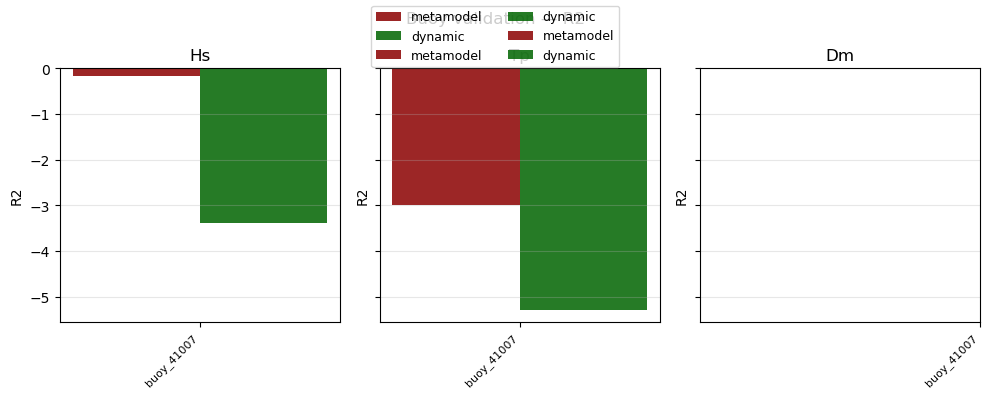

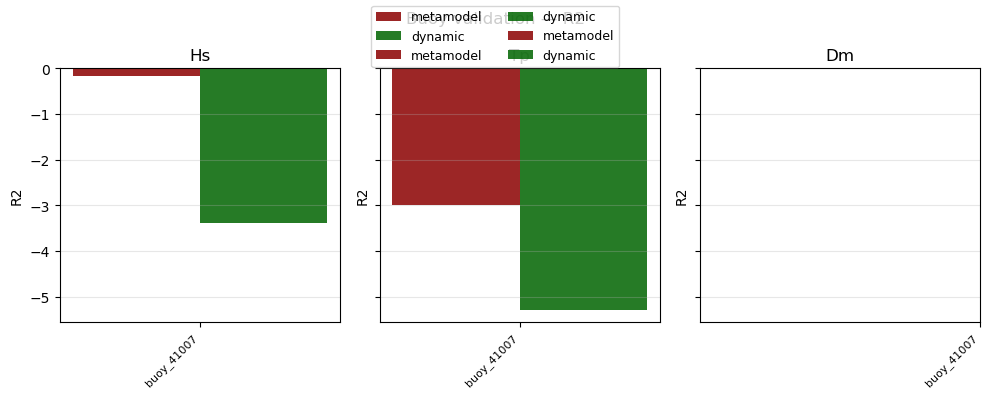

In [4]:
val.plot_buoy_skill(result.metrics, metric="r2")

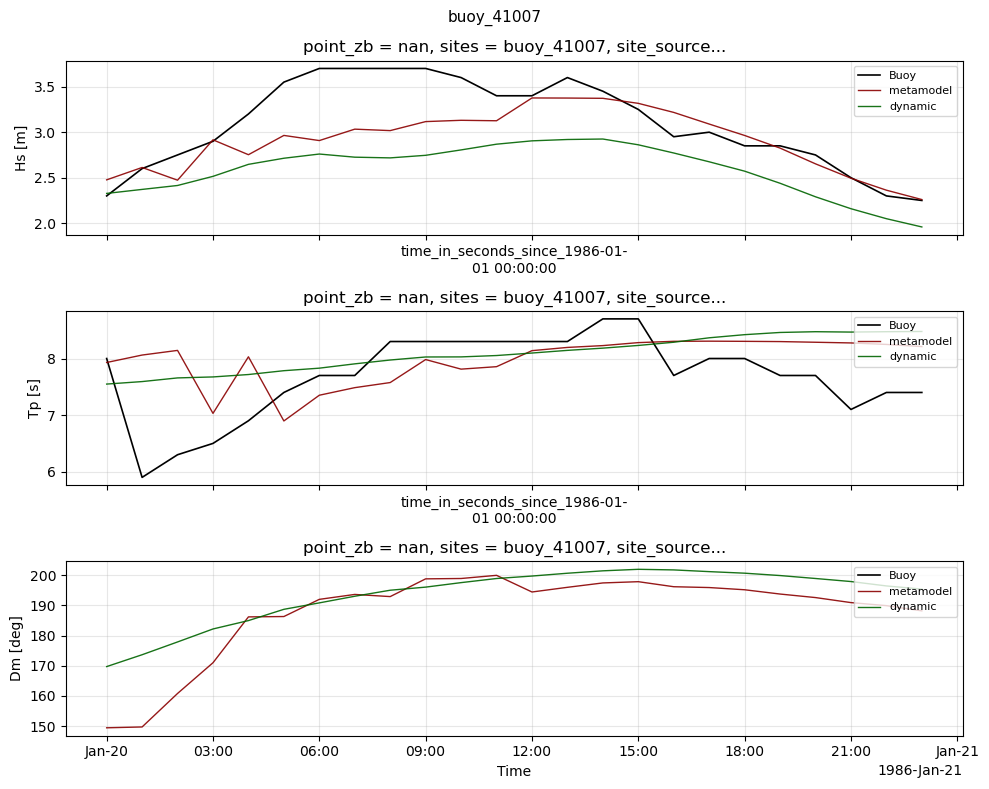

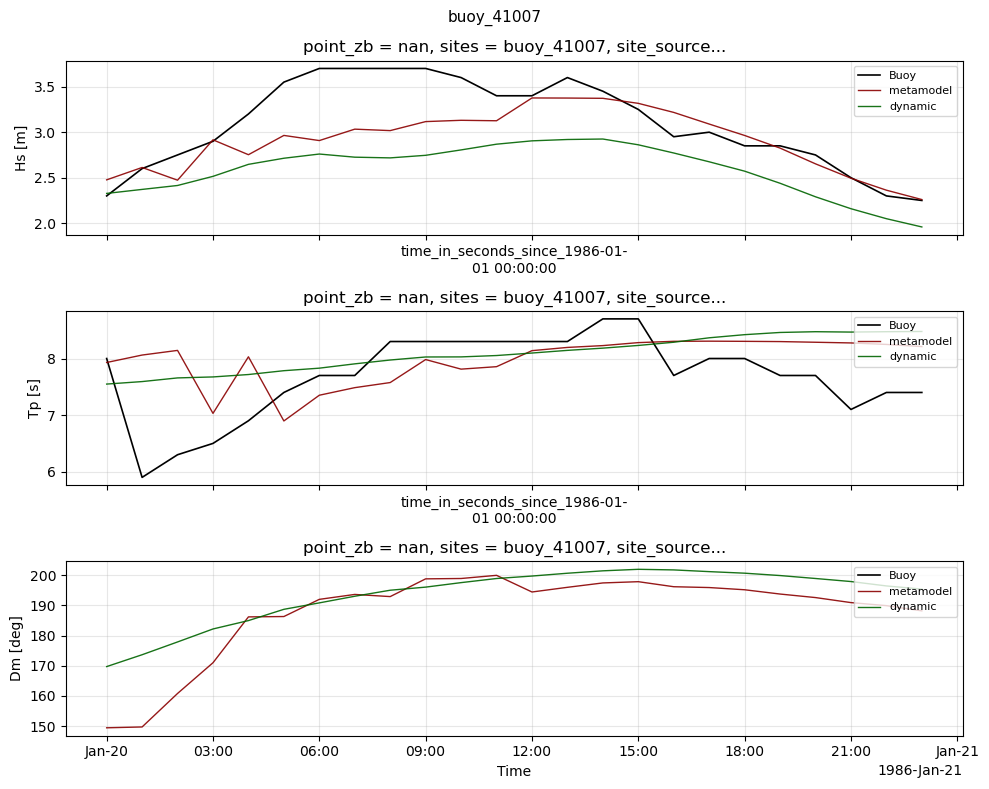

In [5]:
site = result.sites[0]
val.plot_buoy_timeseries(result, site=site)